# Brand Visibility Intelligence — Data Cleaning & EDA

This notebook answers the project's **30 data-cleaning questions** and **30 EDA questions**.

**Data:** the provided `brand_dirty_dataset.csv` (synthetic, 1,320 rows), merged with real
Google Shopping results pulled through SerpApi for the same five keywords. Every row carries a
`data_source` column (`csv` or `api`), because the two behave very differently and several
conclusions only hold for one of them.

**How it's built:** cleaning and feature logic live in `src/` and run via `pipeline.py`. This notebook
calls those same functions, so what you see here is exactly what lands in the SQLite database the
dashboard reads. Part B queries that database with SQL.

**Terminology:** *ranking* = `position` in search results (1 = top). *Rating* = star rating out of 5.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

import config
from src import clean, db, features, load

sns.set_theme(style="whitegrid", palette="deep", font="DejaVu Sans")
plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

SOURCE_COLORS = {"csv": "#8c8c8c", "api": "#2a6fdb"}
MIN_LISTINGS = 3  # brands/platforms with fewer listings are left out of averages to avoid one-off noise
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

def spearman(x, y):
    mask = x.notna() & y.notna()
    r, p = stats.spearmanr(x[mask], y[mask])
    return f"Spearman ρ = {r:+.2f}, p = {p:.3f}, n = {mask.sum()}"

---
## Part A — Data cleaning

`raw` is the merged dataset **before** any cleaning, read with pandas' default type inference so
the type problems are visible. `raw_csv` is the provided CSV alone.

In [2]:
raw_csv = pd.read_csv(config.DIRTY_CSV_PATH)
raw_api = pd.read_csv(config.API_CSV_PATH)
raw = pd.concat(
    [raw_csv.assign(data_source="csv"),
     raw_api[["keyword", "title", "price", "rating", "reviews", "platform", "delivery", "data_source"]]],
    ignore_index=True,
)
raw.head()

,keyword,title,price,rating,reviews,platform,delivery,data_source
0,office chair ergonomic,HP office chair ergonomic Model 603,36225.0,3.70,3241,croma,2 Days,csv
1,microwave oven convection,Samsung microwave oven convection Model 524 !!!,NaN,4.70,1294,amazon,Free Delivery,csv
2,power bank fast charging,Samsung power bank fast charging Model 402,Not Available,NaN,3070,CROMA,Free Delivery,csv
3,microwave oven convection,Dell microwave oven convection Model 877,2507.0,4.70,3446,flipkart,Free Delivery,csv
4,men running shoes,Dell men running shoes Model 536,2176.0,3.80,2031,croma,5 Days,csv


### C1. What is the total number of rows and columns in the dataset?

In [3]:
print("Merged:", raw.shape)
raw.groupby("data_source").size().rename("rows").to_frame()

Merged: (1520, 8)


,rows
data_source,
api,200
csv,1320


**Answer:** The merged raw dataset has **1,520 rows × 8 columns**: 1,320 from the provided CSV and 200 from SerpApi (40 ranked results × 5 keywords). The CSV itself has 7 columns; `data_source` is added on merge. After cleaning and feature engineering, the database table holds **1,421 rows × 24 columns**.

### C2. What are the data types of each column?

In [4]:
pd.DataFrame({"provided CSV": raw_csv.dtypes, "merged": raw.dtypes}).astype(str)

,provided CSV,merged
data_source,nan,object
delivery,object,object
keyword,object,object
platform,object,object
price,object,object
rating,float64,float64
reviews,object,object
title,object,object


**Answer:** In the provided CSV only `rating` is numeric (`float64`). `price` and `reviews` are read as `object` (text). `keyword`, `title`, `platform` and `delivery` are text, as expected.

### C3. Which columns are expected to be numeric but are not?

In [5]:
expected_numeric = ["price", "rating", "reviews"]
{c: str(raw_csv[c].dtype) for c in expected_numeric}

{'price': 'object', 'rating': 'float64', 'reviews': 'object'}

**Answer:** **`price` and `reviews`.** Both should be numbers but load as text. `rating` is already correct.

### C4. Which columns contain missing values?

In [6]:
def placeholder_mask(s):
    return s.astype("string").str.strip().str.lower().isin(config.MISSING_TOKENS) & s.notna()

missing = pd.DataFrame({
    "NaN": raw.isna().sum(),
    "placeholder text": raw.apply(placeholder_mask).sum(),
})

missing["total missing"] = missing.sum(axis=1)
missing[missing["total missing"] > 0]

,NaN,placeholder text,total missing
price,126,66,192
rating,244,0,244
reviews,113,26,139
delivery,21,0,21


**Answer:** **price** (192: 126 blank + 66 "Not Available"), **rating** (244), **reviews** (139: 113 blank + 26 "many") and **delivery** (21, all API rows). `keyword`, `title` and `platform` are complete. The 26 prices of -999 are also effectively missing (see C14), but a NaN check doesn't count them.

### C5. What is the percentage of missing data in each column?

In [7]:
pct = (missing["total missing"] / len(raw) * 100).round(1)
by_source = raw.assign(**{c: raw[c].mask(placeholder_mask(raw[c])) for c in raw.columns}) \
    .groupby("data_source").apply(lambda g: g.isna().mean() * 100, include_groups=False).T.round(1)
by_source.insert(0, "overall %", pct)
by_source[by_source["overall %"] > 0]

data_source,overall %,api,csv
price,12.60,0.00,14.50
rating,16.10,56.50,9.90
reviews,9.10,56.50,2.00
delivery,1.40,10.50,0.00


**Answer:** Overall: rating 16.1%, price 12.6%, reviews 9.1%, delivery 1.4%. The overall figure hides a split: **the CSV's gaps are in price (14.5%)**, while **the API's are in rating and reviews (56.5% each)**, because more than half of Google Shopping listings show no rating at all. API prices are never missing.

### C6. How should missing values in price, rating, and reviews be handled?

In [8]:
cleaned, cleaning_log = clean.clean(load.merge(load.load_csv(), raw_api))
cleaned.groupby("data_source")[["price_imputed", "rating_imputed", "reviews_imputed"]].sum()

,price_imputed,rating_imputed,reviews_imputed
data_source,,,
api,0,109,109
csv,207,121,20


**Answer:** **Fill them; don't drop the rows.** Dropping every row with a gap would remove almost 30% of the data, and more than half of the real API rows.

- **price** → median for the same keyword *and* source (207 CSV rows; no API prices were missing).
- **rating** → median for the same keyword and source (121 CSV, 109 API).
- **reviews** → CSV: keyword median (20 rows). API: **0**, because Google Shopping leaves out the count only when a product has no reviews (109 rows).

Each filled value is flagged in a `*_imputed` column, so any analysis can exclude it. Part B's rating questions do exactly that. Medians are per source because CSV prices are about 4× API prices: a pooled median would fill real gaps with synthetic values.

### C7. Should missing delivery values be filled or labeled as "Unknown"?

In [9]:
print("Missing delivery by source:", raw[raw.delivery.isna()].groupby("data_source").size().to_dict())
cleaned.delivery.value_counts()

Missing delivery by source: {'api': 21}


delivery
Free Delivery    604
2 Days           406
5 Days           390
Unknown           21
Name: count, dtype: int64

**Answer:** **Label them "Unknown".** All 21 are API rows where Google showed no delivery information. There's nothing to infer a value from, and filling in the most common value ("Free Delivery") would overstate free delivery. "Unknown" keeps the row and keeps the gap visible.

### C8. Are there columns with incorrect data types (e.g., price as text)?

In [10]:
for col in ["price", "reviews"]:
    non_numeric = raw_csv[col][pd.to_numeric(raw_csv[col], errors="coerce").isna() & raw_csv[col].notna()]
    print(f"{col}: stored as {raw_csv[col].dtype}; non-numeric values -> {non_numeric.value_counts().to_dict()}")

price: stored as object; non-numeric values -> {'Not Available': 66}
reviews: stored as object; non-numeric values -> {'many': 26}


**Answer:** Yes. `price` is text because 66 cells say "Not Available", and `reviews` is text because 26 cells say "many". A single non-numeric value is enough for pandas to read the whole column as text.

### C9. How do you convert columns like price and reviews into numeric format safely?

In [11]:
sample = pd.Series(["36225.0", "₹1,299.00", "Not Available", "many", "-999", None, "  4,997 "])
pd.DataFrame({"raw": sample, "parsed": clean._to_number(sample)})

,raw,parsed
0,36225.0,"36,225.00"
1,"₹1,299.00","1,299.00"
2,Not Available,NaN
3,many,NaN
4,-999,-999.00
5,None,NaN
6,"4,997","4,997.00"


**Answer:** `clean._to_number` works in three steps:
1. trim and lower-case the value, and turn known placeholders ("not available", "many", "n/a"…) into NaN;
2. strip everything except digits, `.` and `-` (this removes ₹, commas and spaces);
3. `pd.to_numeric(errors="coerce")`, so anything still unparseable becomes NaN instead of crashing.

-999 parses fine as a *number*. It's caught by a separate check (C14), because it's a valid number but an invalid *price*.

### C10. How should invalid values like "Not Available" or "many" be handled?

In [12]:
raw_csv["price"].eq("Not Available").sum(), raw_csv["reviews"].eq("many").sum()

(np.int64(66), np.int64(26))

**Answer:** **Convert them to NaN, then handle them like any other gap (C6).** They can't be repaired: "Not Available" (66 prices) carries no price, and "many" (26 reviews) says there were a lot but not how many. Converting them first is what lets these columns become numeric.

### C11. Are there duplicate rows in the dataset?

In [13]:
print("Exact duplicate rows:", raw.duplicated().sum())
raw[raw.duplicated()].groupby("data_source").size()

Exact duplicate rows: 39


data_source
api     5
csv    34
dtype: int64

**Answer:** Yes, **39 exact duplicate rows**: 34 in the CSV and 5 in the API, where Google listed the same offer twice. Exact matching misses most duplicates, though (see C12).

### C12. What criteria should define a duplicate record (e.g., title + price)?

In [14]:
# The same product listed twice, once with '!!!' appended: invisible to an exact check.
example_title = raw_csv.title[raw_csv.title.str.endswith("!!!")].iloc[0]
base = example_title.replace("!!!", "").strip()
raw_csv[raw_csv.title.str.replace("!!!", "").str.strip().eq(base)]

,keyword,title,price,rating,reviews,platform,delivery
1,microwave oven convection,Samsung microwave oven convection Model 524 !!!,NaN,4.70,1294,amazon,Free Delivery
1314,microwave oven convection,Samsung microwave oven convection Model 524,NaN,4.70,1294,AMAZON,Free Delivery


**Answer:** **Duplicate = same keyword + title + platform + price, compared *after* cleaning.** Title alone is the wrong test: the same model legitimately appears on several platforms at different prices, and those are separate listings that the platform comparison needs. The example above shows why cleaning has to come first. Both rows are the same Samsung listing, but one title ends in "!!!" and the platform is spelled "amazon" in one and "AMAZON" in the other, so an exact check sees two different rows.

### C13. How many duplicate records exist, and how should they be handled?

In [15]:
pre = cleaning_log.set_index("step").loc["remove_duplicates"]
removed = pre.rows_before - pre.rows_after
print(f"Exact duplicates before cleaning: {raw.duplicated().sum()}")
print(f"Duplicates on {config.DUPLICATE_KEYS} after text/price cleaning: {removed}")
print("Rows per source after de-duplication:", cleaned.data_source.value_counts().to_dict())

Exact duplicates before cleaning: 39
Duplicates on ['keyword', 'title', 'platform', 'price'] after text/price cleaning: 99
Rows per source after de-duplication: {'csv': 1226, 'api': 195}


**Answer:** 39 exact duplicates before cleaning, but **99** once titles, platforms and prices are cleaned (94 in the CSV, 5 in the API). The first occurrence is kept and the rest are dropped, leaving **1,226 CSV + 195 API = 1,421 rows**.

### C14. Are there any negative or zero values in the price column?

In [16]:
price_num = pd.to_numeric(raw.price, errors="coerce")
price_num[price_num <= 0].value_counts()

price
-999.00    26
Name: count, dtype: int64

**Answer:** Yes: **26 prices of exactly -999**, a common placeholder for "unknown". There are no zero prices. A product can't cost a negative amount, so these are treated as missing and filled (C6).

### C15. Are there unrealistic or extreme values (outliers) in the dataset?

In [17]:
num = raw.assign(price=price_num, reviews=pd.to_numeric(raw.reviews, errors="coerce"))
num.groupby("data_source")[["price", "rating", "reviews"]].describe().T

data_source         api        csv
price   count    200.00   1,128.00
        mean   6,808.99  33,636.08
        std    8,460.00  56,485.94
        min      399.00    -999.00
        25%    1,778.00  11,067.50
        50%    4,595.00  24,099.50
        75%    9,992.50  38,598.50
        max   93,190.00 498,050.00
rating  count     87.00   1,189.00
        mean       4.50       3.79
        std        0.60       0.71
        min        1.00       2.50
        25%        4.40       3.20
        50%        4.60       3.80
        75%        4.80       4.40
        max        5.00       5.00
reviews count     87.00   1,294.00
        mean     442.80   2,419.90
        std      850.15   1,432.12
        min        1.00      14.00
        25%        5.50   1,126.00
        50%       30.00   2,334.50
        75%      395.00   3,646.75
        max    3,900.00   4,997.00

**Answer:** **Yes, in the CSV.** Prices reach ₹4.98 lakh against a median of ₹24,100. A ₹4.4 lakh power bank or a ₹5 lakh pair of running shoes isn't a real product. These pull the CSV's mean (₹33,600) well above its median. CSV ratings (2.5–5) and reviews (14–4,997) are within normal ranges. API prices run from ₹399 to ₹93,190; the top one is a Faber 83 L built-in microwave, which really is that expensive.

### C16. How should such invalid or inconsistent values be treated?

In [18]:
# missing_after on the last step = product_id / product_link, which only API rows have (not stored in the DB)
cleaning_log

,step,rows_before,rows_after,missing_before,missing_after
0,standardize_columns,1520,1520,4316,4316
1,convert_numeric,1520,1520,4316,4665
2,invalidate_bad_values,1520,1520,4665,4691
3,clean_text,1520,1520,4691,4691
4,standardize_categories,1520,1520,4691,4670
5,remove_duplicates,1520,1421,4670,4349
6,cap_price_outliers,1421,1421,4349,4349
7,impute_missing,1421,1421,4349,2452


**Answer:** The rule: **an impossible value becomes missing, an implausibly extreme one is capped, and nothing is deleted without a reason.** The log shows each step: placeholder text → NaN (`convert_numeric`), -999 → NaN (`invalidate_bad_values`), 99 duplicates removed, CSV outliers capped, then gaps filled and flagged. The 2,452 "missing" cells left after the last step are `product_id` / `product_link`, which only API rows have; they aren't written to the database.

### C17. What is the distribution of the price column?

,median,mean,skew
data_source,,,
api,"4,595.00","6,808.99",5.89
csv,"24,791.00","34,453.24",5.48


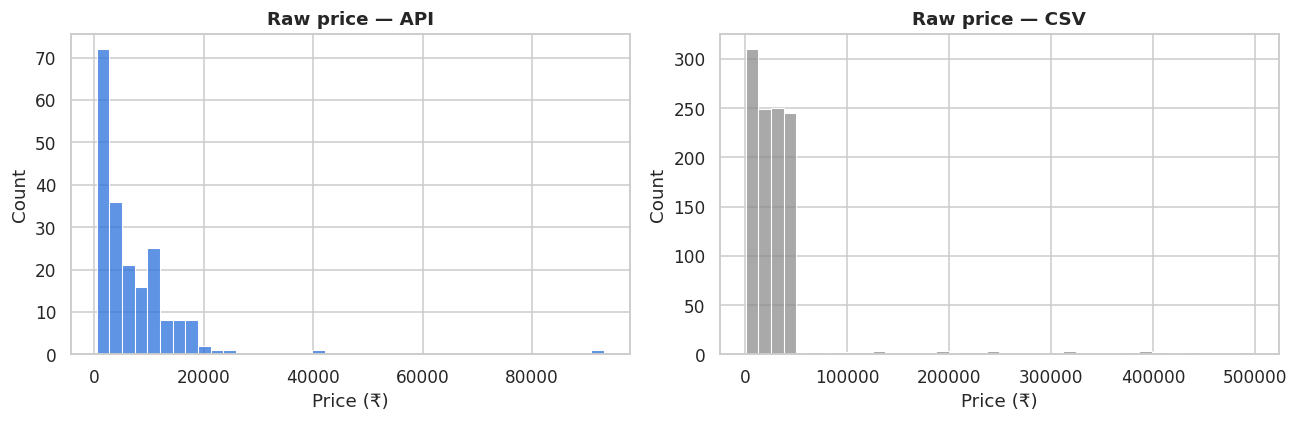

In [19]:
valid = num[num.price > 0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (src, g) in zip(axes, valid.groupby("data_source")):
    sns.histplot(g.price, bins=40, ax=ax, color=SOURCE_COLORS[src])
    ax.set(title=f"Raw price — {src.upper()}", xlabel="Price (₹)")
plt.tight_layout(); save(fig, "c17_raw_price_distribution")
valid.groupby("data_source").price.agg(["median", "mean", "skew"])

**Answer:** **Strongly right-skewed** in both sources (skew ≈ 5.5–5.9): most products are cheap, with a long tail of expensive ones. CSV prices centre on ₹24,800, plus a cluster of extreme errors. API prices centre on ₹4,600, which is realistic for these categories. Because of the skew, the median is the better measure of a typical price, and later charts use a log scale.

### C18. Are there extreme price values compared to the majority?

,median,max,max_over_median
keyword,,,
air fryer India,"24,365.00","489,880.00",20.11
men running shoes,"22,398.00","498,050.00",22.24
microwave oven convection,"24,180.50","482,890.00",19.97
office chair ergonomic,"25,335.00","455,330.00",17.97
power bank fast charging,"27,396.00","436,130.00",15.92


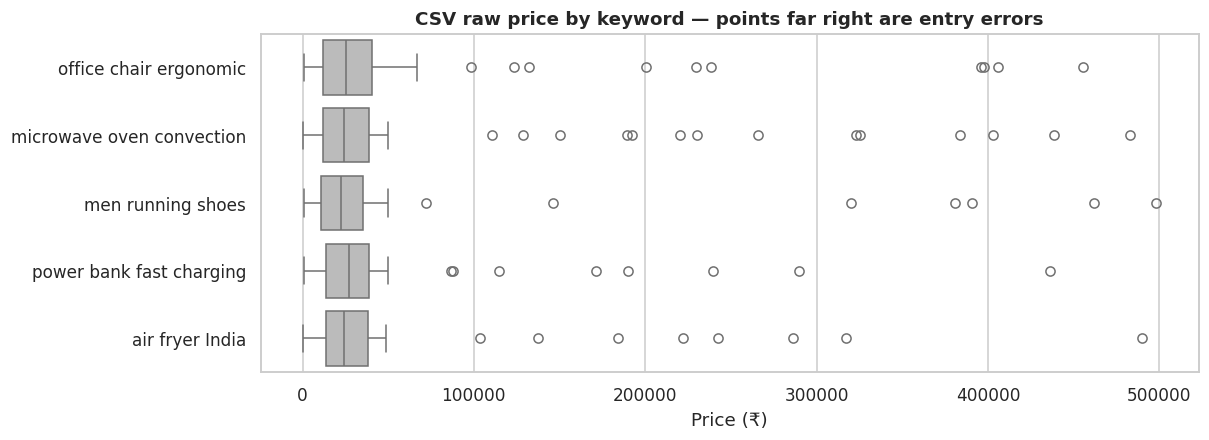

In [20]:
csv_valid = valid[valid.data_source == "csv"]
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=csv_valid, x="price", y="keyword", ax=ax, color="#bbbbbb")
ax.set(title="CSV raw price by keyword — points far right are entry errors", xlabel="Price (₹)", ylabel="")
save(fig, "c18_csv_price_outliers")
csv_valid.groupby("keyword").price.agg(median="median", max="max").assign(max_over_median=lambda d: d["max"] / d["median"])

**Answer:** Yes. In every keyword the CSV's maximum is **16–22× its median**. For men's running shoes, the median is ₹22,398 and the maximum ₹4,98,050. The extreme values sit around 10–20× normal prices, which looks like extra digits typed in by mistake.

### C19. Should outliers be removed or capped? If capped, at what threshold?

In [21]:
g = csv_valid.groupby("keyword").price
fence = (g.quantile(.75) + config.OUTLIER_IQR_MULTIPLIER * (g.quantile(.75) - g.quantile(.25))).rename("cap (₹)")
fence.index = fence.index.str.lower()
fence.to_frame().assign(capped=cleaned[cleaned.data_source == "csv"].groupby("keyword").price_capped.sum())

,cap (₹),capped
keyword,,
air fryer india,"74,392.75",8
men running shoes,"71,731.00",6
microwave oven convection,"79,321.38",14
office chair ergonomic,"83,916.00",10
power bank fast charging,"77,176.38",8


**Answer:** **Capped, not removed.** The rest of each row (title, rating, platform, reviews) is valid, so dropping it would lose data for the brand and platform analysis. The threshold is **Q3 + 1.5 × IQR per keyword** (the standard boxplot fence), which works out to ₹71,700–₹83,900 depending on the keyword. That caps 46 CSV prices, each flagged in `price_capped`. **API prices are not capped:** expensive real products aren't errors. Capping would have cut a ₹12,995 Nike Pegasus down to ₹5,739.

### C20. Are there unwanted characters or noise in the title column (e.g., "!!!")?

In [22]:
noise = raw.title.str.contains(r"!!!")
other = raw.title.str.contains(r"[^\w\s\-&./()+,'\"|:%]")
print("Titles with '!!!':", noise.sum(), "| with other unusual symbols:", (other & ~noise).sum())
raw.loc[noise, "title"].head(3).tolist()

Titles with '!!!': 136 | with other unusual symbols: 4


['Samsung microwave oven convection Model 524 !!!',
 'Boat men running shoes Model 859 !!!',
 'Puma office chair ergonomic Model 198 !!!']

**Answer:** Yes: **136 CSV titles end in "!!!"**. Only 4 other titles contain unusual symbols, all API titles with stray quote marks (e.g. `Shoes'"'by Myntra`).

### C21. How can you clean and standardize product titles?

In [23]:
idx = raw.index[noise][:3]
pd.DataFrame({"before": raw.loc[idx, "title"], "after": clean.clean_text(raw.loc[idx])["title"]})

,before,after
1,Samsung microwave oven convection Model 524 !!!,Samsung microwave oven convection Model 524
10,Boat men running shoes Model 859 !!!,Boat men running shoes Model 859
18,Puma office chair ergonomic Model 198 !!!,Puma office chair ergonomic Model 198


**Answer:** `clean.clean_text` replaces any character that isn't a letter, digit, space or common product punctuation (`- & . / ( ) + , ' "`) with a space, collapses repeated spaces and trims. Brand capitalisation ("HP", "boAt") is left alone, since forcing Title Case would turn "HP" into "Hp". Keywords are lower-cased so that "air fryer India" and "air fryer india" can't split into two groups.

### C22. Are there inconsistencies in text formatting across columns?

In [24]:
for col in ["keyword", "platform", "delivery"]:
    print(f"{col}: {raw[col].nunique()} raw variants, e.g. {raw[col].dropna().unique()[:6].tolist()}")

keyword: 5 raw variants, e.g. ['office chair ergonomic', 'microwave oven convection', 'power bank fast charging', 'men running shoes', 'air fryer India']
platform: 61 raw variants, e.g. ['croma', 'amazon', 'CROMA', 'flipkart', 'RELIANCE DIGITAL', 'AMAZON']
delivery: 9 raw variants, e.g. ['2 Days', 'Free Delivery', '5 Days', 'Free 10 min delivery', 'Free delivery by Fri', 'Free delivery']


**Answer:** Yes.
- **platform:** 61 raw spellings. The CSV has case variants; the API has domain suffixes and sub-stores ("Amazon.in", "Myntra - MNow").
- **delivery:** 9 formats that mix two different things, cost ("Free Delivery") and speed ("2 Days").
- **keyword:** consistent apart from capitalisation ("air fryer India").

### C23. Are platform names consistent (e.g., "amazon", "AMAZON", "Amazon")?

In [25]:
raw_csv.platform.value_counts()

platform
reliance digital    193
amazon              182
flipkart            168
CROMA               164
croma               162
RELIANCE DIGITAL    160
AMAZON              155
FLIPKART            136
Name: count, dtype: int64

**Answer:** **No.** Every CSV platform appears in two spellings: "amazon" (182) and "AMAZON" (155), "croma" and "CROMA", and so on, so 4 platforms look like 8. Uncorrected, every platform chart would show Amazon twice at roughly half its real count.

### C24. How can you standardize categorical values across the dataset?

In [26]:
mapping = pd.DataFrame({"raw": raw.platform, "clean": raw.platform.map(clean._canonical_platform)})
mapping.value_counts().reset_index(name="rows").head(15)

,raw,clean,rows
0,reliance digital,Reliance Digital,193
1,amazon,Amazon,182
2,flipkart,Flipkart,168
3,CROMA,Croma,164
4,croma,Croma,162
5,RELIANCE DIGITAL,Reliance Digital,160
6,AMAZON,Amazon,155
7,FLIPKART,Flipkart,136
8,Amazon.in,Amazon,55
9,Flipkart,Flipkart,18


**Answer:** **Map every raw value to one canonical name.** First strip domain and region suffixes (".in", ".com", " India"). Then match known aliases case-insensitively using `config.PLATFORM_ALIASES`: anything containing "amazon" becomes Amazon, anything containing "reliance" becomes Reliance Digital, and so on. Unknown sellers keep their own name, with tidied capitalisation. The rules live in config, so supporting a new platform takes one line.

### C25. Are delivery values consistent and meaningful?

In [27]:
pd.crosstab(raw.delivery.fillna("<missing>"), raw.data_source)

data_source,api,csv
delivery,,
2 Days,0,435
5 Days,0,422
<missing>,21,0
Free 10 min delivery,5,0
Free Delivery,0,463
Free delivery,119,0
Free delivery by Fri,30,0
Free delivery by Mon,11,0
Free delivery by Thu,11,0


**Answer:** **Only partly.** Within the CSV the values are consistent (Free Delivery / 2 Days / 5 Days), but they mix cost and speed: a "2 Days" product could also be free. **In the API, every listing that shows delivery says it's free** ("Free delivery", "Free delivery by Fri", "Free 10 min delivery"), so the field tells API products apart not at all. It's cleaned to Free Delivery / N Days / Unknown and kept for filtering, but isn't used as a driver in the analysis.

### C26. After cleaning, are there any remaining missing or invalid values?

In [28]:
final = db.query("SELECT * FROM products")

checks = {
    "missing cells": int(final.isna().sum().sum()),
    "price <= 0": int((final.price <= 0).sum()),
    "rating outside 0–5": int((~final.rating.between(0, 5)).sum()),
    "negative reviews": int((final.reviews < 0).sum()),
    "raw_price < price": int((final.raw_price < final.price).sum()),
    "discount outside 0–100%": int((~final.discount_pct.between(0, 100)).sum()),
    "duplicate listings": int(final.duplicated(config.DUPLICATE_KEYS).sum()),
}
checks

{'missing cells': 0,
 'price <= 0': 0,
 'rating outside 0–5': 0,
 'negative reviews': 0,
 'raw_price < price': 0,
 'discount outside 0–100%': 0,
 'duplicate listings': 0}

**Answer:** **No.** Every check passes: no missing cells, no zero or negative prices, no ratings outside 0–5, no negative reviews, no original price below the selling price, no discount outside 0–100%, and no duplicate listings.

### C27. Are all numeric columns correctly formatted and usable?

In [29]:
final[["price", "raw_price", "discount_pct", "rating", "reviews", "position", "visibility_score"]].agg(["dtype", "min", "max"]).T

,dtype,min,max
price,float64,399.00,"93,190.00"
raw_price,float64,499.00,"93,190.00"
discount_pct,float64,0.00,83.00
rating,float64,1.00,5.00
reviews,int64,0,4997
position,int64,1,283
visibility_score,float64,12.27,100.00


**Answer:** **Yes.** Price, discount, rating and visibility are floats; reviews and position are integers. All ranges are plausible: price ₹399–₹93,190, discount 0–83%, position 1–40 for the API (up to 283 for the CSV's row-order positions). The SQLite schema also enforces some of this with CHECK constraints (price > 0, rating between 0 and 5).

### C28. Does the dataset now make logical and business sense?

In [30]:
csv_final = final[final.data_source == "csv"]
pd.crosstab(csv_final.brand, csv_final.keyword)

keyword,air fryer india,men running shoes,microwave oven convection,office chair ergonomic,power bank fast charging
brand,,,,,
Boat,16,36,33,25,25
Dell,34,26,25,19,21
HP,32,28,35,26,36
LG,35,26,33,26,32
Nike,26,29,24,33,23
Philips,28,28,23,31,29
Puma,24,21,35,30,26
Samsung,23,32,24,24,25
Sony,22,18,30,23,26


**Answer:** **It's technically clean, but the CSV doesn't make business sense.** The table shows every one of the 9 CSV brands selling every product: Dell air fryers (34), Nike microwaves (24), Puma power banks (26), HP running shoes (28). Real brands don't do this, so the CSV is synthetic, and brand findings from it describe how it was generated, not the market. Its "positions" are also just row order. **The API data does make sense:** the microwave brands are LG, IFB and Samsung, and the shoe brands are Nike, Puma and Decathlon. That's why Part B relies on API data for brand and ranking conclusions.

### C29. Should products with no ratings or reviews be retained or removed?

In [31]:
final.groupby("data_source")[["rating_imputed", "reviews_imputed"]].mean().mul(100).round(1).add_suffix(" %")

,rating_imputed %,reviews_imputed %
data_source,,
api,55.90,55.90
csv,9.90,1.60


**Answer:** **Keep them.** In the API data 56% of products have no rating. Removing them would throw out half the real market and bias every average toward established products. They stay in with the median rating filled in and `rating_imputed = 1`, and rating analyses use real ratings only.

### C30. Can additional features like brand extraction from title improve the dataset?

In [32]:
print("Distinct brands:", final.groupby("data_source").brand.nunique().to_dict())
final[final.data_source == "api"][["title", "brand"]].sample(8, random_state=1)

Distinct brands: {'api': 95, 'csv': 9}


,title,brand
1358,Cellbell C54 Boss Chair High Back Executive Of...,Cellbell
1242,LG 21 L Convection Microwave Oven,LG
1244,FABER FBIO 83L 18F TFT BK 83L Convection Micro...,Faber
1277,Glen Air Fryer 5.5 Litre Digital Controls 8 Pr...,Glen
1390,Puma Dazzler Sneakers For Men,Puma
1371,Werner Study Chair in Black Colour,Werner
1237,Whirlpool 24 L Convection Microwave Oven,Whirlpool
1253,Midea 24 L Convection Microwave Oven with Air ...,Midea


**Answer:** **Yes. Without it there's no brand analysis at all, because neither source has a brand column.** Extraction looks for a known brand anywhere in the title ("Men's PUMA X SAYSKY…" → Puma), otherwise takes the first word, and labels titles that start with a generic word ("Ergonomic Chairs – …") as Unbranded. It finds **95 brands in the API data**, against the CSV's 9. Other derived features: `visibility_score`, `price_range`, `rating_range`, `discount_pct`, `review_engagement`, `is_top_10`.

---
## Part B — Exploratory data analysis

From here on everything is read from the **SQLite database** (`products` table and the
`brand_summary` / `platform_summary` views), the same source the dashboard uses.

> **Read this before the ranking questions.** The CSV has no real search positions: its `position` is
> just the row order within each keyword, and its brands are random (Puma air fryers, Dell running
> shoes). Ranking conclusions are therefore drawn from the **API data**, which is real Google Shopping
> rank. CSV results are still shown where the brief asks about the whole dataset.

In [33]:
df = db.query("SELECT * FROM products")
api = df[df.data_source == "api"].copy()
rated = df[df.rating_imputed == 0]          # real (not imputed) ratings only
api_rated = api[api.rating_imputed == 0]
# Price relative to the median of the same keyword and source: removes the category effect
# (shoes are cheaper than microwaves) so platforms and brands can be compared fairly.
df["price_index"] = df.price / df.groupby(["data_source", "keyword"]).price.transform("median")
api["price_index"] = df.loc[api.index, "price_index"]
print(df.data_source.value_counts().to_dict())

{'csv': 1226, 'api': 195}


### 🟦 General market analysis

### E1. How many total products are available per keyword?

data_source,api,csv,total
keyword,,,
microwave oven convection,40,262,302
men running shoes,40,244,284
power bank fast charging,40,243,283
air fryer india,40,240,280
office chair ergonomic,35,237,272


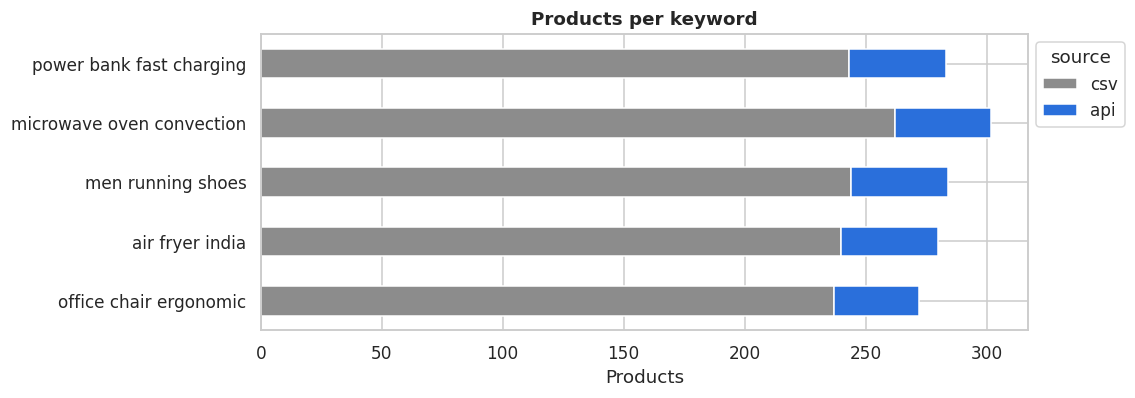

In [34]:
per_kw = db.query("""
    SELECT keyword, data_source, COUNT(*) AS products
    FROM products GROUP BY keyword, data_source
""").pivot(index="keyword", columns="data_source", values="products")
per_kw["total"] = per_kw.sum(axis=1)
ax = per_kw[["csv", "api"]].sort_values("api").plot.barh(stacked=True, color=SOURCE_COLORS, figsize=(9, 3.5))
ax.set(title="Products per keyword", xlabel="Products", ylabel="")
ax.legend(title="source", loc="upper left", bbox_to_anchor=(1, 1)); save(ax.figure, "e01_products_per_keyword")
per_kw.sort_values("total", ascending=False)

**Answer:** Combined, each keyword has **272–302 products**: microwave oven convection the most (302), office chair ergonomic the fewest (272). Every keyword contributes 40 API results, except office chairs (35 after removing 5 duplicates). The CSV adds 237–262 per keyword, so it dominates the counts.

### E2. What is the overall average price of products?

In [35]:
summary = db.query("""
    SELECT 'all' AS data_source, ROUND(AVG(price)) AS avg_price, COUNT(*) AS n FROM products
    UNION ALL
    SELECT data_source, ROUND(AVG(price)), COUNT(*) FROM products GROUP BY data_source
""")
medians = df.groupby("data_source").price.median()
summary["median_price"] = summary.data_source.map({**medians, "all": df.price.median()})
summary

,data_source,avg_price,n,median_price
0,all,"23,781.00",1421,"22,658.00"
1,api,"6,854.00",195,"4,626.00"
2,csv,"26,473.00",1226,"24,594.00"


**Answer:** The overall average is **₹23,781** (median ₹22,658), but it blends two very different datasets: the CSV averages ₹26,473, while **real Google Shopping averages ₹6,854 (median ₹4,626)**. The real market is about 4–5× cheaper than the CSV suggests.

### E3. What is the distribution of price across all products?

,0.10,0.25,0.50,0.75,0.90
data_source,,,,,
api,999.00,"1,720.00","4,626.00","10,014.00","14,860.00"
csv,"5,935.00","14,170.00","24,594.00","36,045.00","46,021.00"


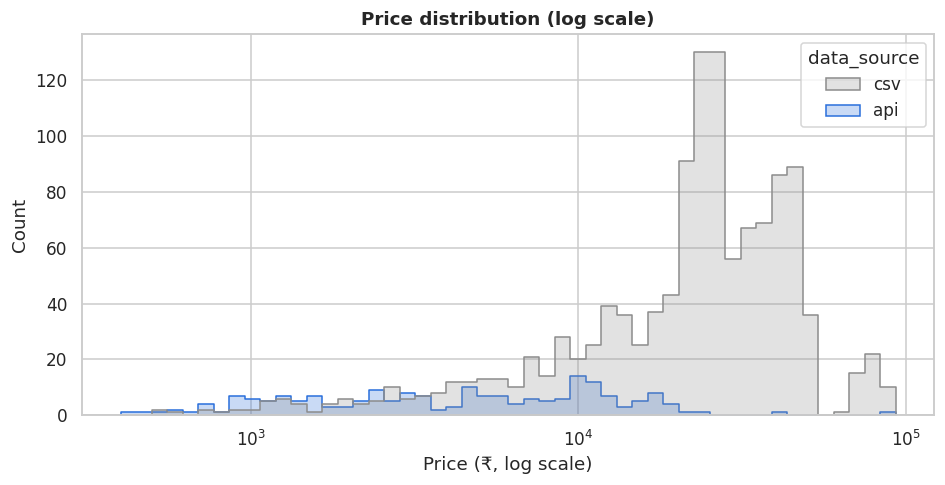

In [36]:
fig, ax = plt.subplots()
sns.histplot(data=df, x="price", hue="data_source", bins=50, log_scale=True, palette=SOURCE_COLORS, ax=ax, element="step")
ax.set(title="Price distribution (log scale)", xlabel="Price (₹, log scale)"); save(fig, "e03_price_distribution")
df.groupby("data_source").price.quantile([.1, .25, .5, .75, .9]).unstack().round()

**Answer:** Right-skewed. **Half of real products cost under ₹4,626 and 90% under ₹14,860**: a mass market with a thin premium tail. CSV prices are spread evenly from about ₹6k to ₹46k (10th–90th percentile), which doesn't resemble real prices for power banks or shoes.

### E4. What is the average rating across all products?

In [37]:
pd.DataFrame({
    "avg rating (all rows)": df.groupby("data_source").rating.mean(),
    "avg rating (real ratings only)": rated.groupby("data_source").rating.mean(),
    "rated products": rated.groupby("data_source").size(),
}).round(2)

,avg rating (all rows),avg rating (real ratings only),rated products
data_source,,,
api,4.65,4.49,86
csv,3.79,3.79,1105


**Answer:** CSV: **3.79**. API: **4.49** counting only real ratings (86 products), or 4.65 including filled values. Real Google Shopping ratings are high and tightly bunched (median 4.6), so a 4.2 is below average in this market.

### E5. How are reviews distributed (low vs high engagement products)?

API: top 10% of products hold 56% of all reviews


count   min   max
data_source review_engagement                   
api         High                   3  3300  3900
            Low                  181     0   883
            Medium                11  1100  2500
csv         High                 471  2974  4997
            Low                  294    14  1093
            Medium               461  1098  2971

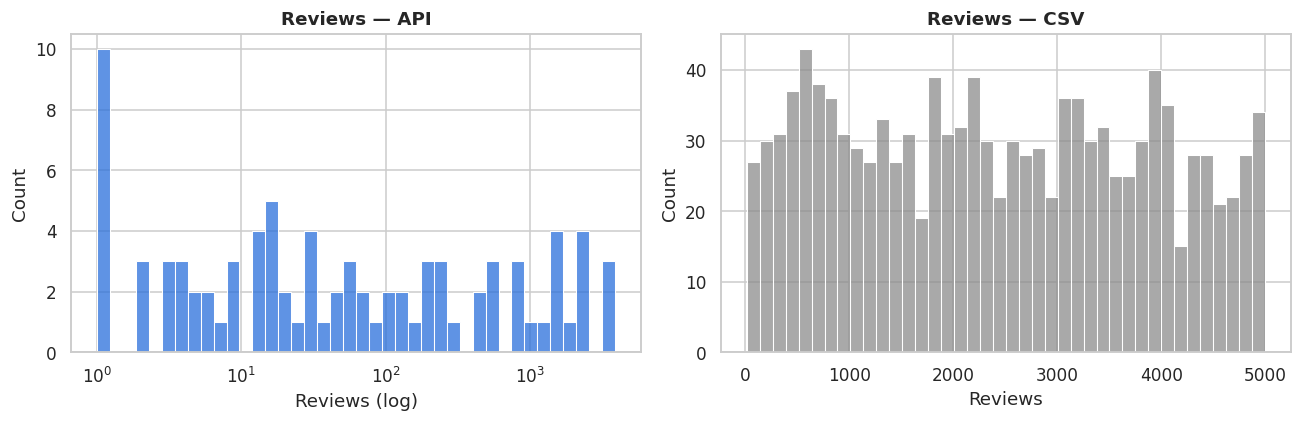

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (src, g) in zip(axes, df[df.reviews_imputed == 0].groupby("data_source")):
    sns.histplot(g.reviews, bins=40, ax=ax, color=SOURCE_COLORS[src], log_scale=(src == "api"))
    ax.set(title=f"Reviews — {src.upper()}", xlabel="Reviews" + (" (log)" if src == "api" else ""))
plt.tight_layout(); save(fig, "e05_reviews_distribution")
api_reviews = api[api.reviews_imputed == 0].reviews.sort_values(ascending=False)
print(f"API: top 10% of products hold {api_reviews.head(len(api_reviews)//10).sum() / api_reviews.sum():.0%} of all reviews")
df.groupby(["data_source", "review_engagement"]).reviews.agg(["count", "min", "max"])

**Answer:** **Very unequal in real data:** the top 10% of reviewed API products hold 56% of all reviews, and 56% of API products have no reviews at all. A handful of products collect most of the social proof, and most API products (181 of 195) fall in the Low tier. CSV reviews are spread evenly from 14 to 4,997, another sign that it's synthetic.

### 🟩 Brand analysis

### E6. Which brand appears most frequently?

,brand,products
0,LG,159
1,HP,157
2,Philips,144
3,Boat,141
4,Puma,140


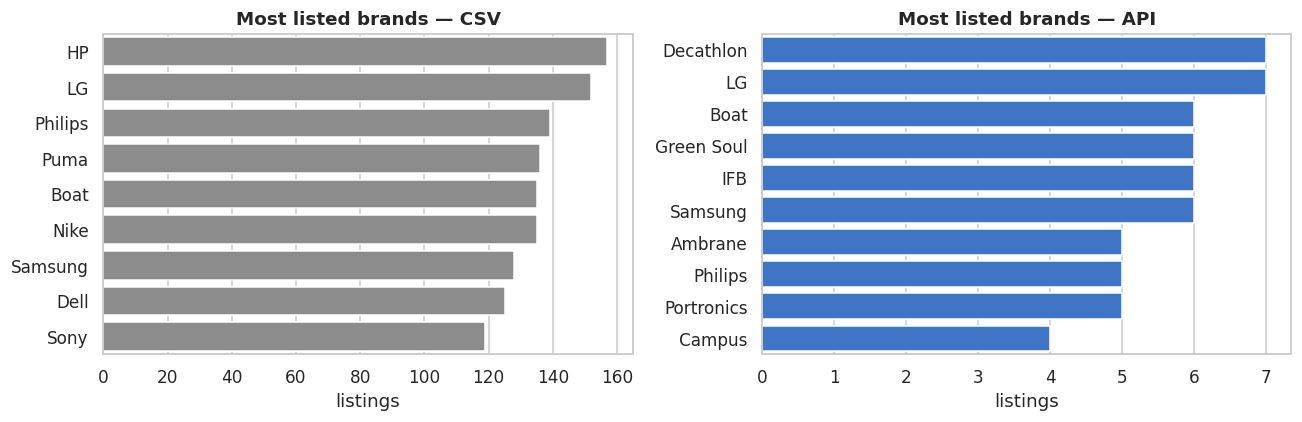

In [39]:
counts = df.groupby(["data_source", "brand"]).size().rename("listings").reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, src in zip(axes, ["csv", "api"]):
    top = counts[(counts.data_source == src) & (counts.brand != "Unbranded")].nlargest(10, "listings")
    sns.barplot(data=top, y="brand", x="listings", ax=ax, color=SOURCE_COLORS[src])
    ax.set(title=f"Most listed brands — {src.upper()}", ylabel="")
plt.tight_layout(); save(fig, "e06_brand_frequency")
db.query("SELECT brand, products FROM brand_summary ORDER BY products DESC LIMIT 5")

**Answer:** Overall: **LG (159), HP (157), Philips (144)**. These counts come from the CSV, where 9 brands share about 1,200 rows almost equally. **In real search results no brand dominates:** Decathlon and LG lead with only 7 listings each out of 195, followed by boAt, Green Soul, IFB and Samsung with 6.

### E7. Which brand has the highest average visibility_score?

In [40]:
vis = db.query("""
    SELECT data_source, brand, COUNT(*) AS listings, ROUND(AVG(visibility_score), 1) AS avg_visibility
    FROM products WHERE brand != 'Unbranded'
    GROUP BY data_source, brand HAVING COUNT(*) >= ?
    ORDER BY data_source, avg_visibility DESC
""", params=(MIN_LISTINGS,))
vis.groupby("data_source").head(5)

,data_source,brand,listings,avg_visibility
0,api,Croma,3,53.20
1,api,Nivia,3,48.80
2,api,Portronics,5,38.60
3,api,LG,7,34.50
4,api,Solara,3,30.90
22,csv,Philips,139,17.20
23,csv,Samsung,128,17.00
24,csv,Dell,125,17.00
25,csv,Puma,136,16.70
26,csv,HP,157,16.50


**Answer:** Among brands with at least 3 API listings: **Croma (53.2), Nivia (48.8), Portronics (38.6), LG (34.5)**. Croma is a retailer's own label, and its listings sit near the top (average position 3.7). In the CSV every brand scores 16.5–17.2, with no real difference between them, as expected from random row order.

### E8. What is the average rating (ranking) per brand?

In [41]:
rank = df[df.brand != "Unbranded"].groupby(["data_source", "brand"]).agg(
    listings=("position", "size"), avg_position=("position", "mean"), avg_rating=("rating", "mean"))
rank = rank[rank.listings >= MIN_LISTINGS].round(2)
rank.loc["api"].sort_values("avg_position").head(10)

,listings,avg_position,avg_rating
brand,,,
Croma,3,3.67,3.67
Nivia,3,14.67,4.47
Samsung,6,15.00,4.68
Lifelong,4,15.50,4.70
Decathlon,7,17.57,4.59
Solara,3,17.67,4.73
Portronics,5,18.20,4.28
Asics,3,18.33,4.53
Nike,3,18.33,4.67


**Answer:** API, brands with at least 3 listings: **Croma ranks best (average position 3.7)**, followed by Nivia (14.7), Samsung (15.0) and Lifelong (15.5). Average position can only be compared within a source: CSV positions run up to 283, API positions only to 40.

### E9. Which brands appear most in top 10 ratings (position <= 10)?

In [42]:
top10 = db.query("""
    SELECT data_source, brand, SUM(is_top_10) AS top_10_listings, COUNT(*) AS listings,
           ROUND(100.0 * SUM(is_top_10) / COUNT(*), 1) AS pct_of_listings_in_top_10
    FROM products WHERE brand != 'Unbranded'
    GROUP BY data_source, brand HAVING SUM(is_top_10) > 0
    ORDER BY data_source, top_10_listings DESC
""")
top10.groupby("data_source").head(6)

,data_source,brand,top_10_listings,listings,pct_of_listings_in_top_10
0,api,Croma,3,3,100.00
1,api,Samsung,2,6,33.30
2,api,Portronics,2,5,40.00
3,api,Morphy Richards,2,2,100.00
4,api,Lifelong,2,4,50.00
5,api,LG,2,7,28.60
34,csv,Dell,9,125,7.20
35,csv,LG,8,152,5.30
36,csv,Puma,6,136,4.40
37,csv,Philips,6,139,4.30


**Answer:** API: **Croma** (all 3 of its listings in the top 10), then Samsung, Portronics, Morphy Richards, Lifelong and LG with 2 each. Top-10 slots are spread thinly and no brand owns the first page. In the CSV, Dell (9) and LG (8) lead, but at 3–7% of their listings that's noise.

### E10. Which brands have the highest average rating?

In [43]:
br = rated[rated.brand != "Unbranded"].groupby(["data_source", "brand"]).rating.agg(["mean", "count"])
br = br[br["count"] >= MIN_LISTINGS].round(2).sort_values("mean", ascending=False)
pd.concat({"api": br.loc["api"].head(6), "csv": br.loc["csv"].head(6)})

mean  count
    brand               
api IFB      4.85      4
    Boat     4.78      4
    Solara   4.73      3
    Philips  4.70      4
    Samsung  4.67      3
    Nike     4.67      3
csv HP       3.87    137
    Sony     3.87    108
    Boat     3.83    119
    Puma     3.83    123
    Philips  3.81    126
    Dell     3.78    116

**Answer:** API (real ratings, at least 3 rated products): **IFB 4.85, boAt 4.78, Solara 4.73, Philips 4.70.** CSV: HP and Sony at 3.87; differences of 0.1 between CSV brands are noise. Each API brand has only 3–4 rated products, so treat these as indicative.

### 🟨 Pricing analysis

### E11. What is the price distribution across different brands?

,keyword,median_price,price_index
brand,,,
Puma,men running shoes,"3,374.00",2.31
Boat,power bank fast charging,"2,199.00",1.57
LG,microwave oven convection,"17,375.50",1.38
Green Soul,office chair ergonomic,"10,990.00",1.29
IFB,microwave oven convection,"15,066.00",1.20
Samsung,microwave oven convection,"10,975.00",1.13
Decathlon,men running shoes,"1,599.00",1.09
Philips,air fryer india,"5,149.00",1.08
Ambrane,power bank fast charging,"1,299.00",0.93


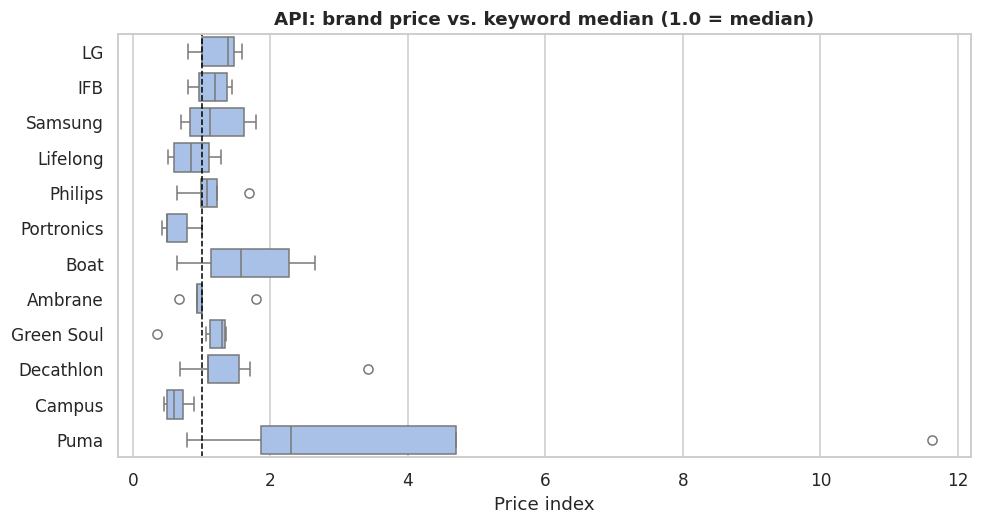

In [44]:
top_brands = api[api.brand != "Unbranded"].brand.value_counts().loc[lambda s: s >= 4].index
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=api[api.brand.isin(top_brands)], y="brand", x="price_index", ax=ax, color="#9fbff0")
ax.axvline(1, color="black", lw=1, ls="--")
ax.set(title="API: brand price vs. keyword median (1.0 = median)", xlabel="Price index", ylabel=""); save(fig, "e11_brand_price_index")
api[api.brand.isin(top_brands)].groupby("brand").agg(keyword=("keyword", lambda s: s.mode()[0]),
    median_price=("price", "median"), price_index=("price_index", "median")).sort_values("price_index", ascending=False).round(2)

**Answer:** The chart compares each brand's prices with the median for its keyword (1.0 = typical). **Puma (2.3×) and boAt (1.6×) price well above their categories.** LG (1.4×) and IFB (1.2×) are the premium microwave brands, while **Portronics (0.5×) and Campus (0.6×) compete on price.** The index removes the category effect: without it, any microwave brand would look expensive next to any shoe brand.

### E12. How are products distributed across price_range categories?

data_source,api,csv,api %,csv %
price_range,,,,
Budget (<₹5k),105,101,53.80,8.20
Mid-range (₹5k–15k),73,223,37.40,18.20
Premium (₹15k–35k),15,574,7.70,46.80
Luxury (₹35k+),2,328,1.00,26.80


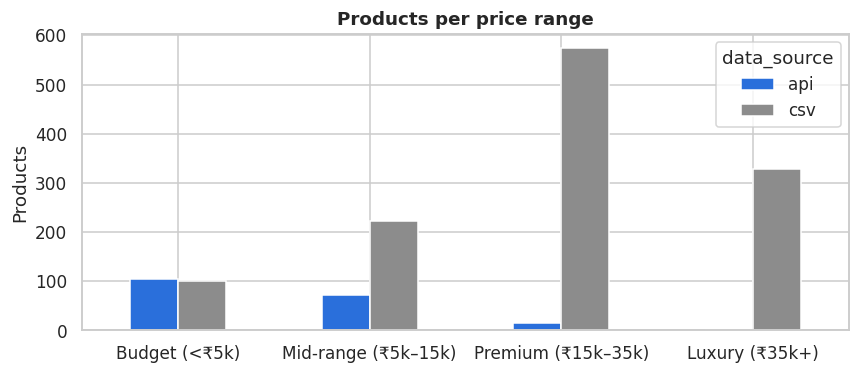

In [45]:
order = [label for _, label in config.PRICE_BANDS]
ct = pd.crosstab(df.price_range, df.data_source).reindex(order)
ax = ct.plot.bar(color=SOURCE_COLORS, figsize=(9, 3.5), rot=0)
ax.set(title="Products per price range", xlabel="", ylabel="Products"); save(ax.figure, "e12_price_range")
ct.assign(**{f"{c} %": (ct[c] / ct[c].sum() * 100).round(1) for c in ct.columns})

**Answer:** **Real market: 54% Budget (under ₹5k), 37% Mid-range, 8% Premium, 1% Luxury.** The CSV is almost the reverse, with 47% Premium and 27% Luxury. For pricing strategy, the real competition is below ₹15k, where 91% of API products sit.

### E13. Do higher-priced products have better rankings (rating)?

In [46]:
rows = []
for kw, g in api.groupby("keyword"):
    r, p = stats.spearmanr(g.price, g.position)
    rows.append({"keyword": kw, "spearman_price_vs_position": round(r, 2), "p": round(p, 3), "n": len(g)})
print("API, all keywords pooled (price index):", spearman(api.price_index, api.position))
print("CSV pooled:", spearman(df[df.data_source == "csv"].price_index, df[df.data_source == "csv"].position))
pd.DataFrame(rows)

API, all keywords pooled (price index): Spearman ρ = +0.05, p = 0.507, n = 195
CSV pooled: Spearman ρ = +0.04, p = 0.160, n = 1226


,keyword,spearman_price_vs_position,p,n
0,air fryer india,-0.07,0.69,40
1,men running shoes,0.04,0.80,40
2,microwave oven convection,0.31,0.05,40
3,office chair ergonomic,-0.10,0.55,35
4,power bank fast charging,0.05,0.76,40


**Answer:** **No.** Across all keywords, price and position are unrelated (ρ = +0.05, p = 0.51). Within keywords, only microwaves show a hint (ρ = +0.31, p = 0.05, i.e. pricier microwaves rank slightly lower), and with five tests one borderline result is expected by chance. Google neither rewards nor penalises price as such.

### E14. What is the average price per platform?

In [47]:
plat = api.groupby("platform").agg(listings=("price", "size"), avg_price=("price", "mean"),
                                   price_index=("price_index", "median"))
plat[plat.listings >= 5].sort_values("price_index").round(2)

,listings,avg_price,price_index
platform,,,
Tradeindia,5,"10,327.03",0.83
Flipkart,18,"11,699.89",0.93
Myntra,18,"2,586.61",0.95
Amazon,55,"6,828.97",0.96
Decathlon,6,"1,465.67",1.09
Pepperfry,7,"10,471.00",1.12
Reliance Digital,9,"8,105.72",1.26
AJIO,6,"2,387.17",1.47
Tata CLiQ,8,"6,660.25",2.11


**Answer:** On raw averages, Flipkart looks the most expensive (₹11,700) and Myntra the cheapest (₹2,587), but that reflects **product mix**: Myntra's results are mostly shoes, Flipkart's mostly microwaves. Compared like for like with the price index, **Amazon (0.96), Flipkart (0.93) and Myntra (0.95) all price close to the market median**, while Tata CLiQ (2.1×) and AJIO (1.5×) list pricier items.

### E15. Which products have the highest price within each keyword?

In [48]:
db.query("""
    SELECT keyword, title, brand, platform, price
    FROM (
        SELECT *, ROW_NUMBER() OVER (PARTITION BY keyword ORDER BY price DESC) AS rn
        FROM products WHERE data_source = 'api'
    ) WHERE rn = 1
    ORDER BY price DESC
""")

,keyword,title,brand,platform,price
0,microwave oven convection,FABER FBIO 83L 18F TFT BK 83L Convection Micro...,Faber,Amazon,"93,190.00"
1,office chair ergonomic,ASTRIDE Ergofit Ergonomic Office Chair for Hom...,Astride,Vardhman Ceramics,"24,998.00"
2,air fryer india,Ember Marvel Air-Fryer Oven,Ember,Ember,"17,999.00"
3,men running shoes,Men's PUMA X SAYSKY MagMax NITRO 2 Running Shoes,Puma,Puma,"16,999.00"
4,power bank fast charging,boAt EnergyShroom PB665 Turbo X Power Bank,Boat,boAt,"3,699.00"


**Answer:** Microwave: **Faber 83 L built-in, ₹93,190** (Amazon). Office chair: ASTRIDE Ergofit, ₹24,998. Air fryer: Ember Marvel air-fryer oven, ₹17,999. Shoes: Puma × SAYSKY MagMax Nitro 2, ₹16,999. Power bank: boAt EnergyShroom PB665, ₹3,699. **Three of the five sell through the brand's own store** (Ember, Puma, boAt) rather than a marketplace.

### 🟥 Discount & offer analysis

### E16. What percentage of products have a non-zero discount?

In [49]:
db.query("""
    SELECT data_source, COUNT(*) AS products, SUM(has_discount) AS discounted,
           ROUND(100.0 * SUM(has_discount) / COUNT(*), 1) AS pct_discounted,
           ROUND(AVG(CASE WHEN has_discount = 1 THEN discount_pct END), 1) AS avg_discount_when_discounted
    FROM products GROUP BY data_source
""")

,data_source,products,discounted,pct_discounted,avg_discount_when_discounted
0,api,195,90,46.20,31.40
1,csv,1226,0,0.00,NaN


**Answer:** **46% of real listings show a discount** (90 of 195), averaging **31% off** when they do. The CSV shows 0%, because it has no original price. Almost half of real listings carry a strike-through price.

### E17. Do discounted products have better rankings (rating)?

In [50]:
cmp = api.groupby("has_discount").agg(products=("position", "size"), median_position=("position", "median"),
                                      pct_in_top_10=("is_top_10", "mean"), avg_rating=("rating", "mean"))
cmp["pct_in_top_10"] *= 100
u = stats.mannwhitneyu(api[api.has_discount == 1].position, api[api.has_discount == 0].position)
print(f"Mann–Whitney U on position: p = {u.pvalue:.3f}")
cmp.round(2)

Mann–Whitney U on position: p = 0.713


,products,median_position,pct_in_top_10,avg_rating
has_discount,,,,
0,105,19.00,27.62,4.64
1,90,21.00,22.22,4.67


**Answer:** **No.** Discounted products have a median position of 21, against 19 for the rest, and 22% reach the top 10 against 28%. That's slightly *worse*, and not significant (p = 0.71). A discount doesn't buy visibility on Google Shopping.

### E18. Which brand offers the highest average discount?

,listings,avg_discount,pct_discounted
brand,,,
Asics,3,54.66,1.00
Whirlpool,3,31.70,1.00
Boat,6,29.88,0.50
Solara,3,29.01,1.00
Ambrane,5,25.81,0.80
Portronics,5,25.30,0.60
Lifelong,4,24.62,0.75
Nike,3,24.50,0.67


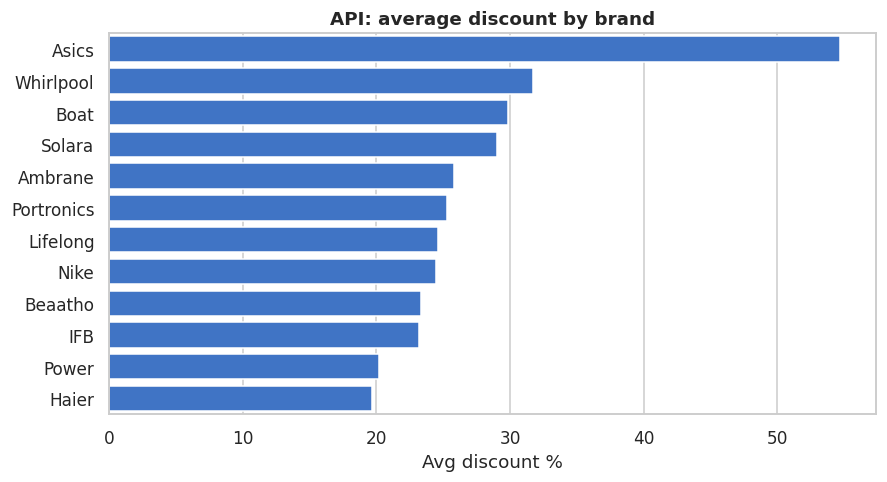

In [51]:
disc_brand = api[api.brand != "Unbranded"].groupby("brand").agg(
    listings=("discount_pct", "size"), avg_discount=("discount_pct", "mean"), pct_discounted=("has_discount", "mean"))
disc_brand = disc_brand[disc_brand.listings >= MIN_LISTINGS].sort_values("avg_discount", ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=disc_brand.head(12).reset_index(), y="brand", x="avg_discount", color=SOURCE_COLORS["api"], ax=ax)
ax.set(title="API: average discount by brand", xlabel="Avg discount %", ylabel=""); save(fig, "e18_discount_by_brand")
disc_brand.head(8).round(2)

**Answer:** Among brands with at least 3 API listings: **Asics (55% on average, every listing discounted)**, Whirlpool (32%), boAt (30%), Solara (29%) and Ambrane (26%). When every listing is discounted this deeply, the list price may be set high on purpose. That's a hypothesis this data can't test.

### E19. Which platform provides the highest average discount?

In [52]:
disc_plat = api.groupby("platform").agg(listings=("discount_pct", "size"), avg_discount=("discount_pct", "mean"),
                                        pct_discounted=("has_discount", "mean"))
disc_plat[disc_plat.listings >= 5].sort_values("avg_discount", ascending=False).round(2)

,listings,avg_discount,pct_discounted
platform,,,
AJIO,6,51.10,1.00
Flipkart,18,35.72,1.00
Myntra,18,34.64,0.67
Reliance Digital,9,15.13,0.67
Amazon,55,4.63,0.31
Tata CLiQ,8,2.94,0.12
Decathlon,6,0.00,0.00
Pepperfry,7,0.00,0.00
Tradeindia,5,0.00,0.00


**Answer:** **AJIO (51%) and Flipkart (36%) show a discount on every listing**, and Myntra averages 35%. Amazon averages only 5% (31% of its listings discounted), and Decathlon and Pepperfry show none. Fashion marketplaces compete on discounts; Amazon shows strike-through prices far less often.

### E20. Is there a relationship between discount and rating?

Discounted API products with real ratings: Spearman ρ = -0.25, p = 0.105, n = 44


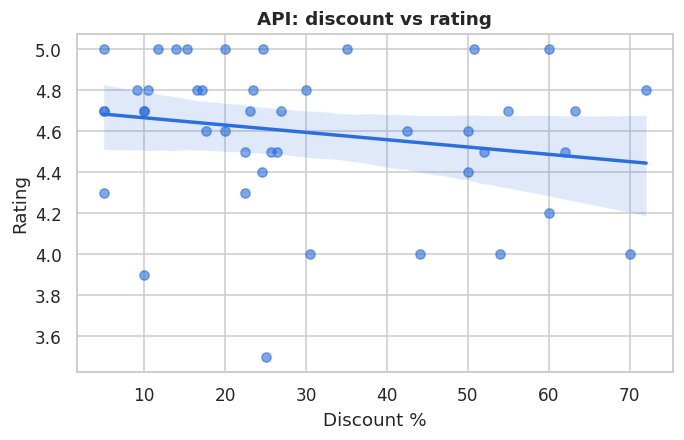

In [53]:
d = api_rated[api_rated.has_discount == 1]
print("Discounted API products with real ratings:", spearman(d.discount_pct, d.rating))
fig, ax = plt.subplots(figsize=(7, 4))
sns.regplot(data=d, x="discount_pct", y="rating", ax=ax, color=SOURCE_COLORS["api"], scatter_kws={"alpha": .6})
ax.set(title="API: discount vs rating", xlabel="Discount %", ylabel="Rating"); save(fig, "e20_discount_vs_rating")

**Answer:** Among discounted API products with real ratings, bigger discounts go with somewhat lower ratings (ρ = −0.25), but the result **isn't significant** (p = 0.11, n = 44). It weakly hints that deep discounts are used to move weaker products; more data is needed to say.

### 🟪 Platform analysis

### E21. Which platform lists the highest number of products?

             platform        
csv          Reliance Digital    324
             Amazon              318
             Croma               300
             Flipkart            284
api (top 6)  Amazon               55
             Flipkart             18
             Myntra               18
             Reliance Digital      9
             Tata CLiQ             8
             Pepperfry             7
Name: count, dtype: int64

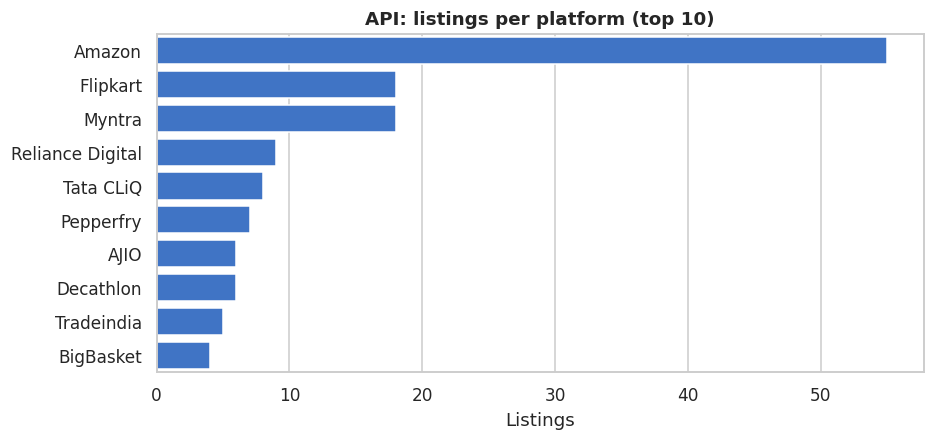

In [54]:
ps = db.query("SELECT platform, products FROM platform_summary ORDER BY products DESC LIMIT 10")
api_ps = api.platform.value_counts().head(10)
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=api_ps.values, y=api_ps.index, color=SOURCE_COLORS["api"], ax=ax)
ax.set(title="API: listings per platform (top 10)", xlabel="Listings", ylabel=""); save(fig, "e21_platform_listings")
pd.concat({"csv": df[df.data_source == "csv"].platform.value_counts(), "api (top 6)": api_ps.head(6)})

**Answer:** **API: Amazon by far, with 55 of 195 listings (28%)**, followed by Flipkart and Myntra with 18 each. The CSV's four platforms are evenly balanced (284–324 each). The real data has a long tail: **47 different sellers** appear in 195 listings, including brand-owned stores.

### E22. Which platform has the highest average rating?

In [55]:
pr = rated.groupby(["data_source", "platform"]).rating.agg(["mean", "count"])
pr[pr["count"] >= 5].round(2).sort_values(["data_source", "mean"], ascending=[True, False])

mean  count
data_source platform                     
api         Tata CLiQ         4.74      5
            Amazon            4.50     23
            Myntra            4.47      9
            AJIO              4.46      5
csv         Croma             3.83    285
            Flipkart          3.81    254
            Amazon            3.80    282
            Reliance Digital  3.74    284

**Answer:** API (real ratings, at least 5 rated products): **Tata CLiQ 4.74**, Amazon 4.50, Myntra 4.47, AJIO 4.46. The differences are small and the samples thin (5–23 products). CSV: Croma 3.83 is highest and Reliance Digital 3.74 lowest, a 0.1 spread that's noise.

### E23. Which platform has the lowest average price?

In [56]:
lp = df.groupby(["data_source", "platform"]).agg(listings=("price", "size"), avg_price=("price", "mean"),
                                                 median_price_index=("price_index", "median"))
lp[lp.listings >= 5].round(2).sort_values(["data_source", "avg_price"])

listings  avg_price  median_price_index
data_source platform                                                 
api         Decathlon                6   1,465.67                1.09
            AJIO                     6   2,387.17                1.47
            Myntra                  18   2,586.61                0.95
            Tata CLiQ                8   6,660.25                2.11
            Amazon                  55   6,828.97                0.96
            Reliance Digital         9   8,105.72                1.26
            Tradeindia               5  10,327.03                0.83
            Pepperfry                7  10,471.00                1.12
            Flipkart                18  11,699.89                0.93
csv         Croma                  300  25,117.60                1.00
            Amazon                 318  26,299.63                1.00
            Flipkart               284  26,498.18                1.00
            Reliance Digital       324  27,876.63                1.00

**Answer:** On raw averages, Decathlon is cheapest in the API (₹1,466) and Croma in the CSV (₹25,118). But Decathlon only sells shoes. Compared like for like with the price index, **Tradeindia (0.83), Flipkart (0.93), Myntra (0.95) and Amazon (0.96) are the cheapest**, and Tata CLiQ (2.11) the most expensive. The CSV platforms are identical by construction (index 1.00).

### E24. What is the average rating (ranking) per platform?

In [57]:
pp = df.groupby(["data_source", "platform"]).agg(listings=("position", "size"), avg_position=("position", "mean"),
                                                 pct_top_10=("is_top_10", "mean"))
pp["pct_top_10"] *= 100
pp[pp.listings >= 5].round(1).sort_values(["data_source", "avg_position"])

listings  avg_position  pct_top_10
data_source platform                                            
api         Pepperfry                7         10.60       71.40
            Decathlon                6         17.30       33.30
            AJIO                     6         18.30       33.30
            Tata CLiQ                8         20.10       25.00
            Myntra                  18         20.60       27.80
            Flipkart                18         21.40       22.20
            Reliance Digital         9         21.60       22.20
            Amazon                  55         21.70       20.00
            Tradeindia               5         28.80        0.00
csv         Amazon                 318        122.30        5.00
            Croma                  300        123.10        5.30
            Reliance Digital       324        123.10        3.10
            Flipkart               284        125.30        2.80

**Answer:** API: **Pepperfry ranks best** (average position 10.6, with 5 of its 7 listings in the top 10) because Google puts its office chairs at the top. **Amazon has by far the most listings but averages position 21.7, with only 20% in the top 10.** Having more listings doesn't mean ranking higher. CSV platforms all average about 123, so there's no signal there.

### E25. Which brands are most frequently listed on each platform?

In [58]:
db.query("""
    WITH counts AS (
        SELECT data_source, platform, brand, COUNT(*) AS listings,
               ROW_NUMBER() OVER (PARTITION BY data_source, platform ORDER BY COUNT(*) DESC, brand) AS rn
        FROM products WHERE brand != 'Unbranded'
        GROUP BY data_source, platform, brand
    ),
    big AS (SELECT data_source, platform FROM products GROUP BY 1, 2 HAVING COUNT(*) >= 7)
    SELECT c.data_source, c.platform, GROUP_CONCAT(c.brand || ' (' || c.listings || ')', ', ') AS top_3_brands
    FROM counts c JOIN big USING (data_source, platform)
    WHERE c.rn <= 3 GROUP BY c.data_source, c.platform ORDER BY c.data_source, c.platform
""")

,data_source,platform,top_3_brands
0,api,Amazon,"Lifelong (3), Nivia (3), Asian (2)"
1,api,Flipkart,"IFB (5), Whirlpool (3), Samsung (2)"
2,api,Myntra,"Ambrane (2), Boat (2), Hrx (2)"
3,api,Pepperfry,Alex (1)
4,api,Reliance Digital,"Samsung (2), Ambrane (1), IFB (1)"
5,api,Tata CLiQ,"Nike (2), Adidas (1), Decathlon (1)"
6,csv,Amazon,"Boat (45), HP (45), Philips (38)"
7,csv,Croma,"HP (40), Nike (37), Sony (37)"
8,csv,Flipkart,"Dell (39), Nike (38), Puma (35)"
9,csv,Reliance Digital,"LG (51), Samsung (41), HP (40)"


**Answer:** **Real platforms specialise.** Flipkart's results are mostly microwave brands (IFB 5, Whirlpool 3, Samsung 2). Tata CLiQ's and AJIO's are shoe brands (Nike, Adidas, Asics, Decathlon). Myntra's are shoes plus power banks (Ambrane, boAt, HRX). In the CSV, every platform carries the same 9 brands in a different order.

### 🟫 Visibility & ranking analysis

### E26. What is the distribution of rating (ranking)?

,min,max,count
keyword,,,
air fryer india,1,40,40
men running shoes,1,40,40
microwave oven convection,1,40,40
office chair ergonomic,1,40,35
power bank fast charging,1,40,40


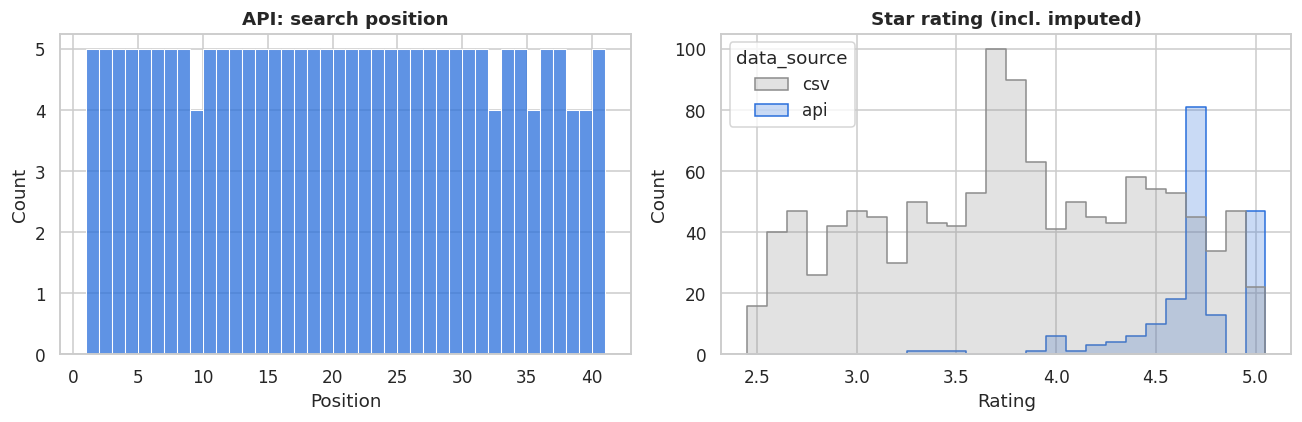

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(api.position, bins=range(1, int(api.position.max()) + 2), ax=axes[0], color=SOURCE_COLORS["api"])
axes[0].set(title="API: search position", xlabel="Position")
sns.histplot(data=df, x="rating", bins=np.arange(2.45, 5.1, .1), ax=axes[1], hue="data_source", palette=SOURCE_COLORS, element="step")
axes[1].set(title="Star rating (incl. imputed)", xlabel="Rating")
plt.tight_layout(); save(fig, "e26_position_and_rating_distribution")
api.groupby("keyword").position.agg(["min", "max", "count"])

**Answer:** API positions are spread evenly from 1 to 40 within each keyword, because each search returns one page of 40. Star ratings: the CSV is spread evenly from 2.5 to 5, while the API bunches at 4.4–4.8, with a spike at the filled-in median.

### E27. Which products have the highest visibility_score?

In [60]:
db.query("""
    SELECT keyword, title, brand, platform, price, position, visibility_score
    FROM products WHERE data_source = 'api' AND position <= 2
    ORDER BY position, keyword
""")

,keyword,title,brand,platform,price,position,visibility_score
0,air fryer india,Pigeon Healthifry Digital Air Fryer,Pigeon,Amazon,"2,649.00",1,100.00
1,men running shoes,Nivia Marathon Running Shoes For Men,Nivia,Amazon,"1,119.00",1,100.00
2,microwave oven convection,LG 28 L Convection Microwave Oven,LG,Neverowned,"10,118.00",1,100.00
3,office chair ergonomic,Ergonomic Chairs - The Specialist Premium Ergo...,Unbranded,Pepperfry,"17,999.00",1,100.00
4,power bank fast charging,Portronics Luxcell B 10K 10000 mAh 22.5W Fast ...,Portronics,Amazon,699.00,1,100.00
5,air fryer india,Morphy Richards 5L Digital Air Fryer,Morphy Richards,Myntra,"4,499.00",2,63.09
6,men running shoes,"Decathlon Men Textile Running Shoes'""'by Myntra",Decathlon,Decathlon,999.00,2,63.09
7,microwave oven convection,Croma 20 Litres Convection Microwave Oven,Croma,BigBasket,"8,490.00",2,63.09
8,office chair ergonomic,Ergonomic Chairs - Akira High Back Breathable ...,Unbranded,Pepperfry,"9,499.00",2,63.09
9,power bank fast charging,Croma 10000 mAh 22.5W Fast Charging Power Bank,Croma,BigBasket,499.00,2,63.09


**Answer:** Position 1 in each keyword scores 100: **Pigeon Healthifry air fryer, Nivia Marathon shoes, LG 28 L microwave, Pepperfry's "The Specialist" chair, and Portronics Luxcell B 10K power bank.** Three of the five top spots are Amazon listings, and three cost under ₹3,000.

### E28. Is there a relationship between rating and rating (ranking)?

API (real ratings): Spearman ρ = +0.00, p = 0.998, n = 86
CSV (real ratings): Spearman ρ = -0.02, p = 0.598, n = 1105


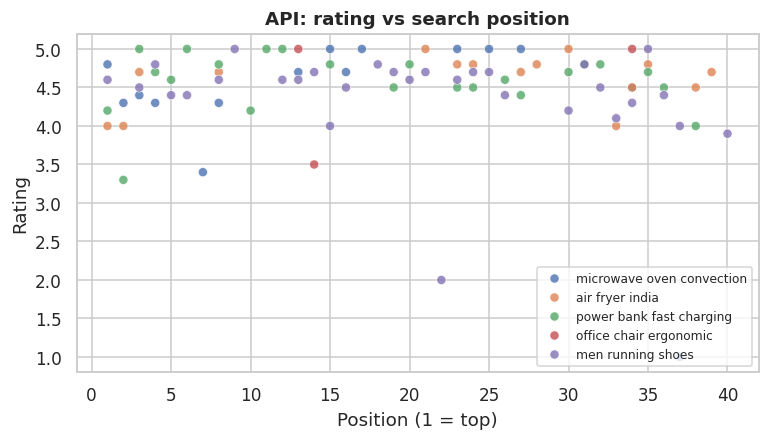

In [61]:
print("API (real ratings):", spearman(api_rated.rating, api_rated.position))
print("CSV (real ratings):", spearman(rated[rated.data_source == "csv"].rating, rated[rated.data_source == "csv"].position))
fig, ax = plt.subplots(figsize=(8, 4))
sns.scatterplot(data=api_rated, x="position", y="rating", hue="keyword", ax=ax, alpha=.8)
ax.set(title="API: rating vs search position", xlabel="Position (1 = top)", ylabel="Rating")
ax.legend(fontsize=8, loc="lower right"); save(fig, "e28_rating_vs_position")

**Answer:** **None.** ρ = 0.00 in the API (p = 1.0) and −0.02 in the CSV. Google Shopping doesn't rank higher-rated products higher.

### E29. Do products with higher reviews rank better?

API, all products: Spearman ρ = -0.08, p = 0.279, n = 195
API, reviewed products only: Spearman ρ = -0.07, p = 0.503, n = 86


,median_reviews,pct_with_reviews
is_top_10,,
0,0.00,41.80
1,2.00,51.00


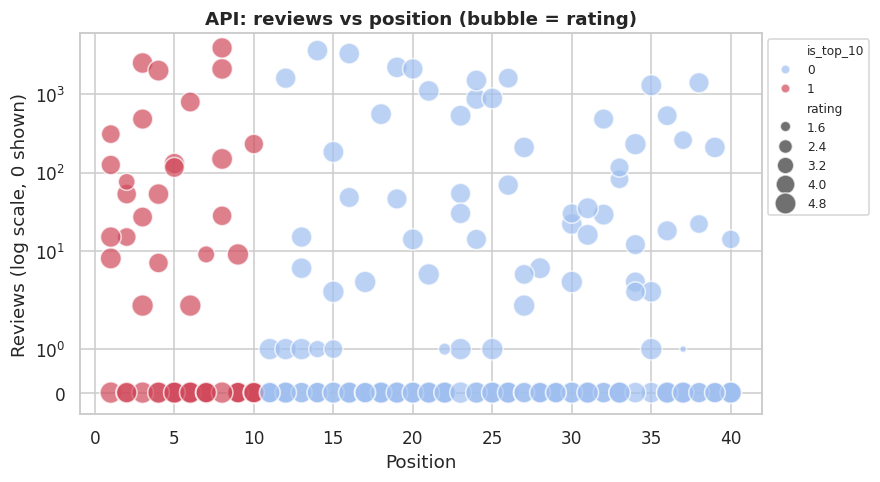

In [62]:
ar = api.copy()  # unreviewed API products carry 0 reviews, which is real information
print("API, all products:", spearman(ar.reviews, ar.position))
print("API, reviewed products only:", spearman(ar[ar.reviews > 0].reviews, ar[ar.reviews > 0].position))
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.scatterplot(data=ar, x="position", y="reviews", size="rating", hue="is_top_10", sizes=(20, 200),
                palette={0: "#9fbff0", 1: "#d1495b"}, ax=ax, alpha=.7)
ax.set(yscale="symlog", ylim=(-0.5, 6000), title="API: reviews vs position (bubble = rating)", xlabel="Position", ylabel="Reviews (log scale, 0 shown)")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
save(fig, "e29_reviews_vs_position")
ar.groupby("is_top_10").agg(median_reviews=("reviews", "median"), pct_with_reviews=("reviews", lambda r: (r > 0).mean() * 100)).round(1)

**Answer:** **Barely.** Products in the top 10 are a little more likely to have any reviews (51% vs 42%), but the number of reviews doesn't correlate with position (ρ = −0.08, p = 0.28; among reviewed products only, −0.07). If anything, having reviews at all matters more than how many, and even that effect is small.

### E30. Which combination of factors (price, rating, reviews) influences top-ranking products?

Top-10 vs rest (API) — medians, except has_rating = share with a real rating:


,price_index,rating,log_reviews,discount_pct,has_rating
is_top_10,,,,,
0,1.01,4.70,0.00,0.00,0.42
1,0.96,4.70,1.10,0.00,0.51


Cross-validated ROC AUC: 0.55 ± 0.04  (0.5 = no better than chance)

price_index    -0.48
has_rating     -0.10
discount_pct   -0.09
rating         -0.08
log_reviews     0.37
dtype: float64

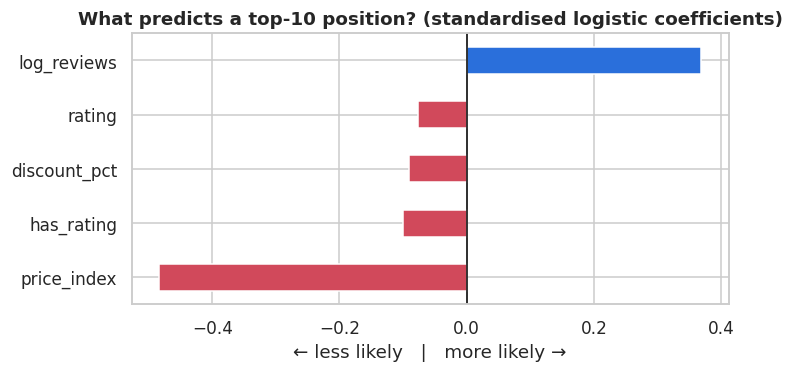

In [63]:
model_df = api.assign(log_reviews=np.log1p(api.reviews), has_rating=(api.rating_imputed == 0).astype(int))
factors = ["price_index", "rating", "log_reviews", "discount_pct", "has_rating"]
print("Top-10 vs rest (API) — medians, except has_rating = share with a real rating:")
profile = model_df.groupby("is_top_10")[factors].median()
profile["has_rating"] = model_df.groupby("is_top_10").has_rating.mean()
display(profile.round(2))

X = StandardScaler().fit_transform(model_df[factors])
logit = LogisticRegression(class_weight="balanced").fit(X, model_df.is_top_10)
from sklearn.model_selection import cross_val_score
auc = cross_val_score(LogisticRegression(class_weight="balanced"), X, model_df.is_top_10, cv=5, scoring="roc_auc")
print(f"Cross-validated ROC AUC: {auc.mean():.2f} ± {auc.std():.2f}  (0.5 = no better than chance)")
coef = pd.Series(logit.coef_[0], index=factors).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.2))
coef.plot.barh(ax=ax, color=["#d1495b" if v < 0 else "#2a6fdb" for v in coef])
ax.axvline(0, color="black", lw=1)
ax.set(title="What predicts a top-10 position? (standardised logistic coefficients)", xlabel="← less likely   |   more likely →")
save(fig, "e30_top10_drivers")
coef.round(2)

**Answer:** Top-10 products are slightly cheaper for their category (price index 0.96 vs 1.01) and slightly more often reviewed. In a logistic model, more reviews (+0.37) and a lower relative price (−0.48) point toward the top 10. **But the model barely beats a coin flip (cross-validated AUC 0.55 ± 0.04).** Price, rating, reviews and discount together explain very little of the ranking, so Google's ranking must depend mainly on things this dataset doesn't capture, probably query relevance, merchant signals and paid placement. That is itself the key finding of this section.

---
## Key insights

1. **The provided CSV is synthetic and can't support brand or ranking conclusions.** Every brand sells every category, positions are just row order, and every ranking test on it comes out at ρ ≈ 0. Real insights come from the API data.
2. **Visibility can't be bought with price, discounts or ratings.** None of the three correlates with search position, and together with review count they predict a top-10 spot barely better than chance (AUC 0.55). For a brand, the realistic levers are presence (more listings, more sellers) and relevance (titles that match what shoppers search for), not discounting.
3. **Having more listings doesn't mean ranking higher.** Amazon carries 28% of all listings but only 20% of them reach the top 10. Pepperfry has 7 listings and 5 of them are in the top 10. A specialist seller can out-rank a big marketplace in its niche.
4. **The real market is budget-led.** 91% of products are under ₹15k and the median is ₹4,626. A launch priced above ₹15k enters a thin segment, about 9% of listings, where it is easier to stand out but has fewer buyers.
5. **Discounting is a platform habit, not a ranking strategy.** AJIO and Flipkart discount every listing, Amazon only 31% of its listings, and discounted products don't rank better (p = 0.71).
6. **Social proof is scarce and concentrated.** 56% of real products have no reviews, and the top 10% of reviewed products hold 56% of all reviews. For a new product, getting its first reviews is the realistic way to stand out.
7. **Brand-owned stores compete directly with marketplaces.** Puma, boAt and Ember sell through their own stores on Google Shopping, and they list the most expensive item in three of the five keywords.

**Limitations:** one snapshot taken on 17 Oct 2026; 40 results per keyword; India locale only; 56% of API ratings missing; small per-brand samples (3–7 listings). Treat brand-level API rankings as directional.